In [ ]:
# 1. Connect Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Project paths
import os
import pandas as pd
PROJECT_DIR = '/content/drive/MyDrive/ECG_Vision_App'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')

# 3. Restore the dataset onto the fast Colab disk
!unzip -q -n {DATA_DIR}/ptb-xl-100hz.zip -d /content

# 4. Load your saved labels
data = pd.read_csv(os.path.join(DATA_DIR, 'af_vs_normal_labels.csv'), index_col='ecg_id')
print(data['split'].value_counts())

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = '/content/drive/MyDrive/ECG_Vision_App'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')

os.makedirs(DATA_DIR, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Contents:", os.listdir(PROJECT_DIR))

Project folder: /content/drive/MyDrive/ECG_Vision_App
Contents: ['data']


In [ ]:
!rm -f /content/ptb-xl-1.0.3.zip
!pip install -q awscli
!aws s3 sync --no-sign-request --region us-east-1 s3://physionet-open/ptb-xl/1.0.3/ /content/ptb-xl --exclude "records500/*" --only-show-errors
!du -sh /content/ptb-xl
!ls /content/ptb-xl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 32.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.
613M	/content/ptb-xl
example_physionet.py  ptbxl_v102_changelog.txt	records100
LICENSE.txt	      ptbxl_v103_changelog.txt	scp_statements.csv
ptbxl_database.csv    RECORDS			SHA256SUMS.txt


In [ ]:
!cd /content && zip -qr ptb-xl-100hz.zip ptb-xl

import shutil
ZIP_DRIVE = os.path.join(DATA_DIR, 'ptb-xl-100hz.zip')
shutil.copy('/content/ptb-xl-100hz.zip', ZIP_DRIVE)

print("Saved to Drive:", ZIP_DRIVE)
print("Size: %.2f GB" % (os.path.getsize(ZIP_DRIVE) / 1e9))

Saved to Drive: /content/drive/MyDrive/ECG_Vision_App/data/ptb-xl-100hz.zip
Size: 0.38 GB


In [ ]:
import pandas as pd

DB_PATH = '/content/ptb-xl/ptbxl_database.csv'
df = pd.read_csv(DB_PATH, index_col='ecg_id')

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (21799, 27)


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [ ]:
df['sex'].value_counts(normalize=True)

,proportion
sex,
0,0.52085
1,0.47915


In [ ]:
df[['scp_codes', 'report', 'strat_fold']].head(10)

,scp_codes,report,strat_fold
ecg_id,,,
1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",sinusrhythmus periphere niederspannung,3
2,"{'NORM': 80.0, 'SBRAD': 0.0}",sinusbradykardie sonst normales ekg,2
3,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,5
4,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,3
5,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,4
6,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,4
7,"{'NORM': 100.0, 'SR': 0.0}","sinusrhythmus linkstyp t abnormal, wahrscheinl...",7
8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",sinusrhythmus linkstyp qrs(t) abnormal infe...,9
9,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,10


In [ ]:
import ast

print("Before:", type(df['scp_codes'].iloc[0]))
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval)
print("After:", type(df['scp_codes'].iloc[0]))

has_afib = df['scp_codes'].apply(lambda codes: 'AFIB' in codes)
has_norm = df['scp_codes'].apply(lambda codes: 'NORM' in codes)

print("AFIB records:", has_afib.sum())
print("NORM records:", has_norm.sum())
print("Both NORM and AFIB:", (has_afib & has_norm).sum())

Before: <class 'str'>
After: <class 'dict'>
AFIB records: 1514
NORM records: 9514
Both NORM and AFIB: 37


In [ ]:
is_sr = df['scp_codes'].apply(lambda codes: 'SR' in codes)

af_df = df[has_afib]
normal_df = df[has_norm & is_sr & ~has_afib]

print("AF group:", len(af_df))
print("Normal group:", len(normal_df))

AF group: 1514
Normal group: 8204


In [ ]:
af_df = af_df.assign(label=1)
normal_df = normal_df.assign(label=0)
data = pd.concat([normal_df, af_df])

def which_split(fold):
    if fold <= 8:
        return 'train'
    elif fold == 9:
        return 'val'
    else:
        return 'test'

data['split'] = data['strat_fold'].apply(which_split)

pd.crosstab(data['split'], data['label'], margins=True)

label,0,1,All
split,,,
test,815,152,967
train,6548,1211,7759
val,841,151,992
All,8204,1514,9718


In [ ]:
LABELS_PATH = os.path.join(DATA_DIR, 'af_vs_normal_labels.csv')

data[['patient_id', 'filename_lr', 'strat_fold', 'split', 'label']].to_csv(LABELS_PATH)

print("Saved:", LABELS_PATH)

Saved: /content/drive/MyDrive/ECG_Vision_App/data/af_vs_normal_labels.csv


In [14]:
!pip install -q wfdb
import wfdb

PTB_DIR = '/content/ptb-xl'

normal_id = data[(data['label'] == 0) & (data['split'] == 'train')].index[0]
af_id = data[(data['label'] == 1) & (data['split'] == 'train')].index[0]

def load_ecg(ecg_id):
    path = os.path.join(PTB_DIR, data.loc[ecg_id, 'filename_lr'])
    signal, meta = wfdb.rdsamp(path)
    return signal, meta

sig_normal, meta = load_ecg(normal_id)
sig_af, _ = load_ecg(af_id)

print("Normal ECG id:", normal_id, "| AF ECG id:", af_id)
print("Signal shape:", sig_normal.shape)
print("Sampling rate:", meta['fs'], "Hz")
print("Leads:", meta['sig_name'])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.1 MB/s eta 0:00:00
Normal ECG id: 1 | AF ECG id: 282
Signal shape: (1000, 12)
Sampling rate: 100 Hz
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


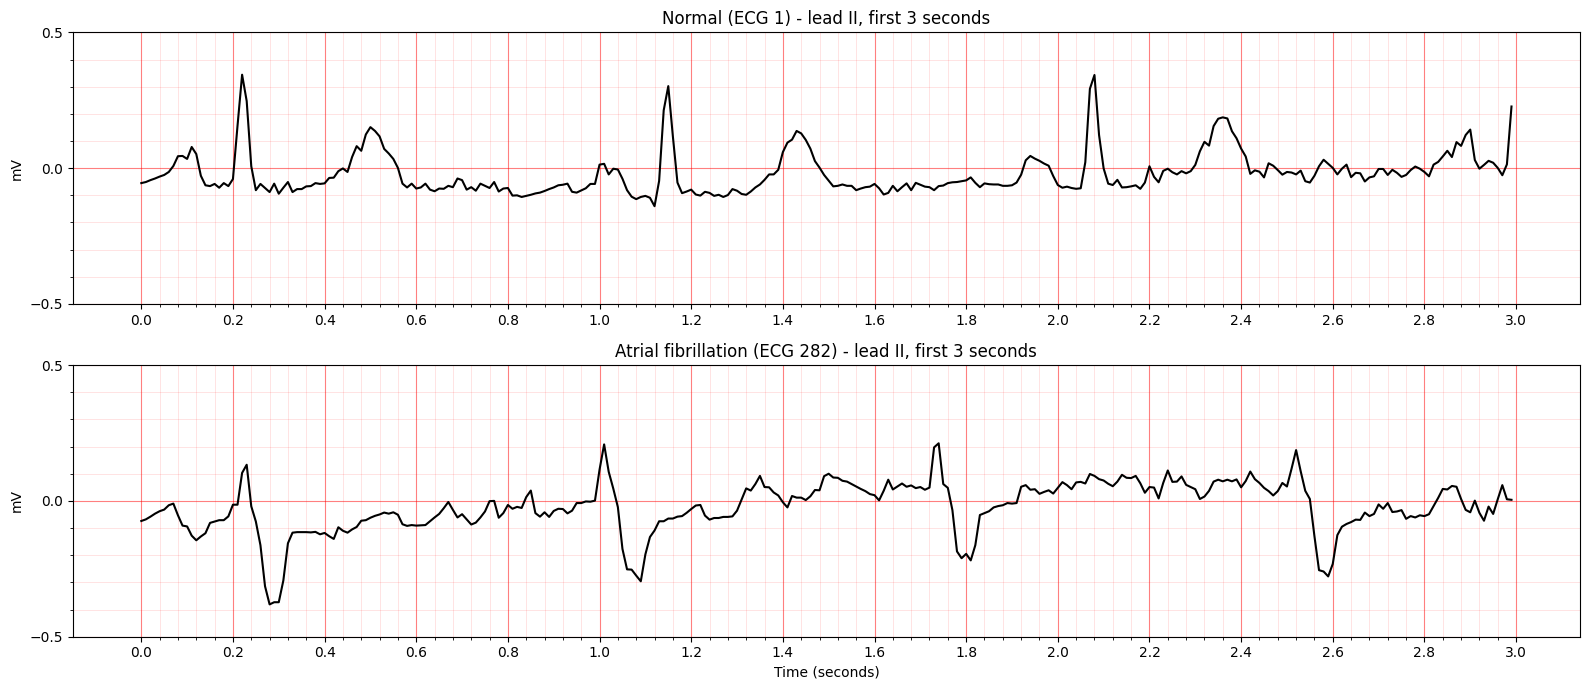

In [17]:
import numpy as np
import matplotlib.pyplot as plt

t = np.arange(sig_normal.shape[0]) / meta['fs']

fig, axes = plt.subplots(2, 1, figsize=(16, 7))

for ax, sig, title in zip(axes, [sig_normal, sig_af],
                          [f'Normal (ECG {normal_id})', f'Atrial fibrillation (ECG {af_id})']):
    lead_ii = sig[:300, 1]
    ax.plot(t[:300], lead_ii, color='black', linewidth=1.5)
    ax.set_title(title + ' - lead II, first 3 seconds')
    ax.set_ylabel('mV')
    ax.set_xticks(np.arange(0, 3.01, 0.2))
    ax.set_xticks(np.arange(0, 3.01, 0.04), minor=True)
    ax.set_yticks(np.arange(-0.5, 0.51, 0.5))
    ax.set_yticks(np.arange(-0.5, 0.51, 0.1), minor=True)
    ax.set_ylim(-0.5, 0.5)
    ax.grid(which='major', color='red', alpha=0.5, linewidth=0.8)
    ax.grid(which='minor', color='red', alpha=0.2, linewidth=0.4)

axes[1].set_xlabel('Time (seconds)')
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'normal_vs_af_lead2.png'), dpi=150)
plt.show()